
# Spam Message Classification Using NLP

## Project Objective
Build a machine learning model that classifies text messages as Spam or Ham (Not Spam).

## Technologies
- Python
- Pandas and NumPy
- Scikit-learn
- CountVectorizer (Bag of Words)
- Multinomial Naive Bayes

## Workflow
1. Load and inspect the dataset.
2. Clean and validate the data.
3. Convert labels into numerical values.
4. Split the dataset into training and testing sets.
5. Convert messages into numerical features.
6. Train a Naive Bayes classifier.
7. Evaluate model performance.
8. Predict new messages.
# New Section

**Import libraries**

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from IPython.display import display

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

file_path = "/content/spam.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (5572, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCategory distribution:")
print(df["Category"].value_counts(dropna=False))


Column names:
['Category', 'Message']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:
Category    0
Message     0
dtype: int64

Duplicate rows: 415

Category distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64


In [4]:

# Keep only the columns needed for this project
df = df[["Category", "Message"]].copy()

# Remove rows with missing labels or messages
df = df.dropna(subset=["Category", "Message"])

# Standardize category labels and message text
df["Category"] = df["Category"].astype(str).str.strip().str.lower()
df["Message"] = df["Message"].astype(str).str.strip()

# Remove empty messages and invalid categories
df = df[df["Message"] != ""]
df = df[df["Category"].isin(["ham", "spam"])]

# Remove exact duplicate records
df = df.drop_duplicates(subset=["Category", "Message"]).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("\nUpdated category distribution:")
print(df["Category"].value_counts())

display(df.head())


Cleaned dataset shape: (5157, 2)

Updated category distribution:
Category
ham     4516
spam     641
Name: count, dtype: int64


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


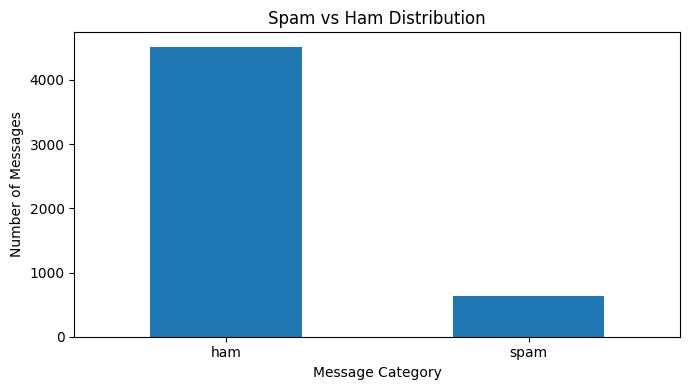

Category
ham     4516
spam     641
Name: count, dtype: int64


In [5]:

category_counts = df["Category"].value_counts()

category_counts.plot(
    kind="bar",
    figsize=(7, 4),
    xlabel="Message Category",
    ylabel="Number of Messages",
    title="Spam vs Ham Distribution",
    rot=0
)

plt.tight_layout()
plt.show()

print(category_counts)


In [6]:

df["spam"] = df["Category"].map({
    "ham": 0,
    "spam": 1
})

print("Label mapping:")
print("Ham  = 0")
print("Spam = 1")

display(df[["Category", "Message", "spam"]].head())


Label mapping:
Ham  = 0
Spam = 1


,Category,Message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [7]:

X = df["Message"]
y = df["spam"]

print("Number of messages:", len(X))
print("Number of labels:", len(y))

print("\nExample message:")
print(X.iloc[0])

print("\nExample label:")
print(y.iloc[0])


Number of messages: 5157
Number of labels: 5157

Example message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Example label:
0


In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training samples: 4125
Testing samples: 1032

Training class distribution:
spam
0    0.876
1    0.124
Name: proportion, dtype: float64

Testing class distribution:
spam
0    0.876
1    0.124
Name: proportion, dtype: float64


In [9]:

vectorizer = CountVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1
)

X_train_cv = vectorizer.fit_transform(X_train)
X_test_cv = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_cv.shape)
print("Testing feature matrix:", X_test_cv.shape)

print("\nFirst 20 vocabulary terms:")
print(vectorizer.get_feature_names_out()[:20])


Training feature matrix: (4125, 42593)
Testing feature matrix: (1032, 42593)

First 20 vocabulary terms:
['00' '00 per' '00 sub' '00 subs' '000' '000 bonus' '000 cash'
 '000 homeowners' '000 pounds' '000 price' '000 prize' '000 xmas' '000pes'
 '000pes so' '008704050406' '008704050406 sp' '01223585236'
 '01223585236 xx' '01223585334' '01223585334 to']


In [10]:

model = MultinomialNB(alpha=1.0)

model.fit(X_train_cv, y_train)

print("Model training completed!")


Model training completed!


In [11]:

y_pred = model.predict(X_test_cv)

results = pd.DataFrame({
    "Actual": y_test.map({0: "Ham", 1: "Spam"}),
    "Predicted": pd.Series(y_pred, index=y_test.index).map({
        0: "Ham",
        1: "Spam"
    }),
    "Message": X_test
})

display(results.head(10))


,Actual,Predicted,Message
3615,Ham,Ham,Can you plz tell me the ans. BSLVYL sent via f...
1387,Ham,Ham,You intrepid duo you! Have a great time and se...
3750,Ham,Ham,R u in this continent?
3867,Ham,Ham,"Cool, want me to go to kappa or should I meet ..."
2302,Ham,Ham,I'm meeting Darren...
1662,Ham,Ham,Then u better go sleep.. Dun disturb u liao.. ...
205,Ham,Ham,"Aight yo, dats straight dogg"
4592,Ham,Ham,Hey do you want anything to buy:)
3133,Ham,Ham,"No worries, hope photo shoot went well. have a..."
1189,Ham,Ham,"sir, you will receive the account no another 1..."


In [12]:

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f} ({accuracy:.2%})")

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        digits=4,
        zero_division=0
    )
)


Accuracy: 0.9806 (98.06%)

Classification Report:

              precision    recall  f1-score   support

         Ham     0.9804    0.9978    0.9890       904
        Spam     0.9821    0.8594    0.9167       128

    accuracy                         0.9806      1032
   macro avg     0.9813    0.9286    0.9529      1032
weighted avg     0.9806    0.9806    0.9801      1032



,Predicted Ham,Predicted Spam
Actual Ham,902,2
Actual Spam,18,110


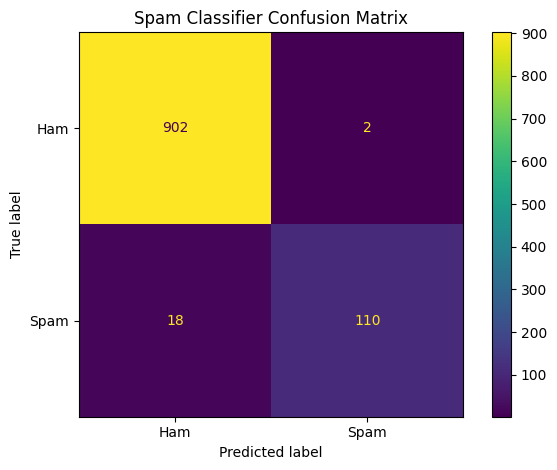

In [13]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display(
    pd.DataFrame(
        cm,
        index=["Actual Ham", "Actual Spam"],
        columns=["Predicted Ham", "Predicted Spam"]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
).plot(values_format="d")

plt.title("Spam Classifier Confusion Matrix")
plt.tight_layout()
plt.show()


In [14]:

new_messages = [
    "Hey, are we meeting tomorrow?",
    "Congratulations! You have won a free prize. Claim now!",
    "URGENT! You have been selected for a cash reward. Call now!",
    "Please send me the assignment notes."
]

new_messages_cv = vectorizer.transform(new_messages)

predictions = model.predict(new_messages_cv)
probabilities = model.predict_proba(new_messages_cv)

for message, prediction, probability in zip(
    new_messages,
    predictions,
    probabilities
):
    label = "Spam" if prediction == 1 else "Ham"
    confidence = probability[int(prediction)]

    print("-" * 60)
    print("Message:", message)
    print("Prediction:", label)
    print(f"Estimated class probability: {confidence:.2%}")


------------------------------------------------------------
Message: Hey, are we meeting tomorrow?
Prediction: Ham
Estimated class probability: 100.00%
------------------------------------------------------------
Message: Congratulations! You have won a free prize. Claim now!
Prediction: Spam
Estimated class probability: 100.00%
------------------------------------------------------------
Message: URGENT! You have been selected for a cash reward. Call now!
Prediction: Spam
Estimated class probability: 100.00%
------------------------------------------------------------
Message: Please send me the assignment notes.
Prediction: Ham
Estimated class probability: 99.99%


In [15]:

def classify_message(message):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please enter a non-empty text message.")

    message_vector = vectorizer.transform([message])

    prediction = int(model.predict(message_vector)[0])
    probabilities = model.predict_proba(message_vector)[0]

    return {
        "message": message,
        "prediction": "Spam" if prediction == 1 else "Ham",
        "spam_probability": round(float(probabilities[1]), 4),
        "ham_probability": round(float(probabilities[0]), 4)
    }


result = classify_message(
    "Congratulations! Claim your free reward now."
)

display(pd.DataFrame([result]))


,message,prediction,spam_probability,ham_probability
0,Congratulations! Claim your free reward now.,Spam,1.0,0.0


In [16]:

user_message = input("Enter a message to check: ")

try:
    result = classify_message(user_message)

    print("\nClassification Result")
    print("=" * 30)
    print("Message:", result["message"])
    print("Prediction:", result["prediction"])
    print(f"Spam probability: {result['spam_probability']:.2%}")
    print(f"Ham probability: {result['ham_probability']:.2%}")

except ValueError as error:
    print(error)


Enter a message to check: hey! you won a prize worth 20 million

Classification Result
Message: hey! you won a prize worth 20 million
Prediction: Spam
Spam probability: 95.94%
Ham probability: 4.06%


In [17]:

import joblib

artifacts = {
    "vectorizer": vectorizer,
    "model": model
}

joblib.dump(artifacts, "/content/spam_classifier.joblib")

print("Model and vectorizer saved successfully!")


Model and vectorizer saved successfully!
